# 07 — GSTT1: how much of a reported suicide marker is a germline deletion?

Kim et al. 2022 listed GSTT1 among the proteins lower in suicide and proposed it as a potential biomarker.
*GSTT1* is one of the best-known gene-deletion polymorphisms in humans: a large fraction of people, in East Asia roughly half, carry no functional copy.

Three questions are asked of this re-analysis:

1. Do donors split into two clusters, with **every** GSTT1 peptide low in the same donors (a whole-gene effect, unlike the single-peptide effect of ALDH2\*2 in notebook 06)?
2. How much of the suicide-control difference is explained by the uneven distribution of the two clusters between the groups?
3. Is any difference left once the cluster is taken into account, and is it unusual compared with the rest of the proteome?

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"
SEARCH = ROOT / "results_large" / "search_ALL_SETS"
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
samples = meta["sample"].tolist()
is_suicide = (meta["group"] == "suicide").to_numpy()

In [2]:
gene = pd.read_csv(SEARCH / "tmt-report" / "ratio_gene_MD.tsv", sep="\t").set_index("Index")
pep = pd.read_csv(SEARCH / "tmt-report" / "ratio_peptide_MD.tsv", sep="\t", low_memory=False)
g = gene.loc["GSTT1", samples].astype(float)
order = g.sort_values()
gap_at = order.diff().iloc[5:-5].idxmax()
low = g < g[gap_at]
meta["GSTT1_log2"] = g.to_numpy(); meta["GSTT1_low"] = low.to_numpy()
print("largest gap between consecutive donors: %.2f log2 units" % order.diff().iloc[5:-5].max())
pd.crosstab(meta["group"], meta["GSTT1_low"].map({True: "low cluster", False: "high cluster"}))

largest gap between consecutive donors: 0.33 log2 units


GSTT1_low,high cluster,low cluster
group,,
control,10,3
suicide,11,12


## 1. All GSTT1 peptides move together

In [3]:
p = pep[(pep["Gene"] == "GSTT1") & ~pep["ProteinID"].astype(str).str.contains("_")].set_index("Peptide")[samples].astype(float)
p = p[p.notna().sum(axis=1) >= 27]
delta = p.loc[:, low.to_numpy()].mean(axis=1) - p.loc[:, ~low.to_numpy()].mean(axis=1)
print(len(p), "GSTT1 peptides quantified in at least three TMT sets")
print("low - high cluster, log2: min %.2f, median %.2f, max %.2f; all negative: %s" % (delta.min(), delta.median(), delta.max(), bool((delta < 0).all())))
pd.DataFrame({"low - high (log2)": delta.round(2)}).sort_values("low - high (log2)")

6 GSTT1 peptides quantified in at least three TMT sets
low - high cluster, log2: min -1.35, median -0.70, max -0.47; all negative: True


,low - high (log2)
Peptide,
VEAAVGEDLFQEAHEVILK,-1.35
KNDIPFELR,-1.19
GQHLSDAFAQVNPLK,-0.70
QRVEAAVGEDLFQEAHEVILK,-0.69
VPDYWYPQDLQAR,-0.55
GLELYLDLLSQPCR,-0.47


## 2 and 3. Group comparison with and without the deletion status

In [4]:
import statsmodels.api as sm
y = meta["GSTT1_log2"].to_numpy(); grp = is_suicide.astype(float); dl = meta["GSTT1_low"].to_numpy().astype(float)
t_all = stats.ttest_ind(y[is_suicide], y[~is_suicide], equal_var=False)
m1 = sm.OLS(y, sm.add_constant(grp)).fit()
m2 = sm.OLS(y, sm.add_constant(np.c_[grp, dl])).fit()
tab = [[int((low & is_suicide).sum()), int((~low & is_suicide).sum())], [int((low & ~is_suicide).sum()), int((~low & ~is_suicide).sum())]]
res = pd.Series({
    "suicide - control, unadjusted (log2)": round(m1.params[1], 3), "p, unadjusted (Welch)": round(t_all.pvalue, 3),
    "suicide - control, adjusted for cluster (log2)": round(m2.params[1], 3), "p, adjusted": round(m2.pvalues[1], 3),
    "low cluster among suicide": f"{tab[0][0]}/23", "low cluster among controls": f"{tab[1][0]}/13",
    "Fisher p, cluster vs group": round(stats.fisher_exact(tab)[1], 3),
    "variance of GSTT1 explained by cluster (R2)": round(sm.OLS(y, sm.add_constant(dl)).fit().rsquared, 2),
})
for name, sel in [("within low cluster", low.to_numpy()), ("within high cluster", ~low.to_numpy())]:
    t = stats.ttest_ind(y[sel & is_suicide], y[sel & ~is_suicide], equal_var=False)
    res[f"p, suicide vs control {name}"] = round(t.pvalue, 2)
res.to_csv(RES / "GSTT1_deletion_summary.tsv", sep="\t", header=False)
res

suicide - control, unadjusted (log2)             -0.333
p, unadjusted (Welch)                             0.011
suicide - control, adjusted for cluster (log2)   -0.133
p, adjusted                                       0.007
low cluster among suicide                         12/23
low cluster among controls                         3/13
Fisher p, cluster vs group                        0.159
variance of GSTT1 explained by cluster (R2)        0.87
p, suicide vs control within low cluster           0.24
p, suicide vs control within high cluster          0.01
dtype: object

### Context: how common is a group difference of this size?

In [5]:
G = gene[samples].astype(float).dropna()
d_all = G.loc[:, is_suicide].mean(axis=1) - G.loc[:, ~is_suicide].mean(axis=1)
p_all = stats.ttest_ind(G.loc[:, is_suicide], G.loc[:, ~is_suicide], axis=1, equal_var=False).pvalue
resid = abs(m2.params[1])
print(f"genes quantified in all donors: {len(G)}")
print(f"genes with unadjusted Welch p < 0.01 between groups: {100 * (p_all < 0.01).mean():.0f}%")
print(f"genes with an absolute group difference at least as large as the adjusted GSTT1 difference ({resid:.2f} log2): {100 * (d_all.abs() >= resid).mean():.0f}%")
explained = 1 - m2.params[1] / m1.params[1]
print(f"share of the unadjusted GSTT1 difference removed by adjusting for the cluster: {100 * explained:.0f}%")

genes quantified in all donors: 8402
genes with unadjusted Welch p < 0.01 between groups: 14%
genes with an absolute group difference at least as large as the adjusted GSTT1 difference (0.13 log2): 9%
share of the unadjusted GSTT1 difference removed by adjusting for the cluster: 60%


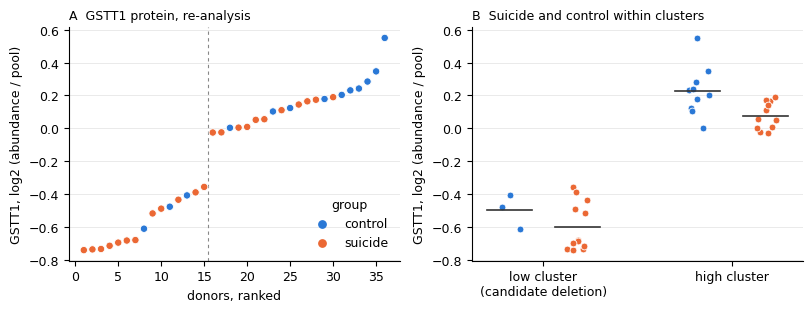

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.2))
rank = meta.sort_values("GSTT1_log2").reset_index(drop=True)
ax[0].scatter(rank.index + 1, rank["GSTT1_log2"], s=28, c=[COL[x] for x in rank["group"]], edgecolor="white", linewidth=0.6, zorder=3)
ax[0].axvline(int(low.sum()) + 0.5, color="#888888", lw=0.8, ls=(0, (3, 3)))
ax[0].set_xlabel("donors, ranked"); ax[0].set_ylabel("GSTT1, log2 (abundance / pool)")
ax[0].set_title("A  GSTT1 protein, re-analysis", fontsize=9, loc="left")
for lab, c in COL.items():
    ax[0].scatter([], [], s=28, color=c, label=lab)
ax[0].legend(frameon=False, title="group", loc="lower right")
rng = np.random.default_rng(1)
for i, (name, sel) in enumerate([("low cluster", low.to_numpy()), ("high cluster", ~low.to_numpy())]):
    for j, (grp_name, gsel) in enumerate([("control", ~is_suicide), ("suicide", is_suicide)]):
        v = y[sel & gsel]; x = i + (j - 0.5) * 0.36
        ax[1].scatter(x + rng.uniform(-0.06, 0.06, len(v)), v, s=24, color=COL[grp_name], edgecolor="white", linewidth=0.6, zorder=3)
        ax[1].plot([x - 0.12, x + 0.12], [v.mean(), v.mean()], color="#333333", lw=1.2, zorder=4)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["low cluster\n(candidate deletion)", "high cluster"])
ax[1].set_ylabel("GSTT1, log2 (abundance / pool)")
ax[1].set_title("B  Suicide and control within clusters", fontsize=9, loc="left")
for a_ in ax:
    a_.grid(axis="y", color="#e6e6e6", lw=0.6); a_.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_GSTT1_deletion.png", dpi=300); plt.show()

## Conclusion

- GSTT1 abundance is bimodal and all of its peptides shift together, as expected for the common *GSTT1* gene deletion. The cluster alone explains most of the variance of GSTT1 between donors.
- Deletion-like donors are more frequent among the suicide cases than among the controls in this small cohort (not significantly so), and this imbalance accounts for the larger part of the reported group difference.
- A smaller difference remains after adjusting for the cluster. It cannot be interpreted from these data: the high cluster mixes donors with one and two gene copies, which the proteome cannot separate, and a group difference of at least this size is seen for about one gene in ten in this cohort (see the cell above).

GSTT1 is therefore not a specific marker: its variation between donors is dominated by an inherited deletion.
Without genotypes the remaining difference cannot be assigned to gene dosage or to the disease. The MOSAIC-S design measures the genome of every donor alongside the proteome to separate exactly these two sources.